# Task 2: Conditional GAN (CGAN) — Oxford-102 Flowers

**Objective:** Build a Conditional Generative Adversarial Network (CGAN) that generates basic flower visuals conditioned on a flower category.

This notebook extends the same **Oxford-102 Flowers** project used in Tasks 3 and 4. To keep GAN training practical on Google Colab, this experiment uses five visually distinct categories from the same dataset: **daffodil, sunflower, rose, lotus, and hibiscus**.

### What this notebook demonstrates
- Loading the same Oxford-102 images and official labels
- Selecting a representative subset of flower categories
- Image preprocessing for GAN training
- A class-conditioned Generator and Discriminator
- Adversarial training
- Generator/Discriminator loss curves
- Category-controlled image generation
- Saving the trained models and generated samples

> **Recommended runtime:** Google Colab GPU (`Runtime → Change runtime type → T4 GPU`).


## 1. Install and import libraries


In [1]:
!pip install -q scipy pillow matplotlib pandas tqdm


In [2]:
import os
import random
import tarfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.io
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.utils import make_grid, save_image

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)
if DEVICE.type != "cuda":
    print("Tip: Enable a T4 GPU in Colab for much faster training.")


Using device: cuda


## 2. Download the Oxford-102 Flowers dataset

The notebook uses the same official University of Oxford VGG image archive and label file as Task 4.


In [3]:
DATA_DIR = Path("flowers_data")
DATA_DIR.mkdir(exist_ok=True)

IMAGES_URL = "https://www.robots.ox.ac.uk/~vgg/data/flowers/102/102flowers.tgz"
LABELS_URL = "https://www.robots.ox.ac.uk/~vgg/data/flowers/102/imagelabels.mat"

images_tgz = DATA_DIR / "102flowers.tgz"
labels_path = DATA_DIR / "imagelabels.mat"
jpg_dir = DATA_DIR / "jpg"

if not images_tgz.exists():
    print("Downloading Oxford-102 images...")
    urllib.request.urlretrieve(IMAGES_URL, images_tgz)

if not labels_path.exists():
    print("Downloading labels...")
    urllib.request.urlretrieve(LABELS_URL, labels_path)

if not jpg_dir.exists():
    print("Extracting images...")
    with tarfile.open(images_tgz) as tar:
        tar.extractall(DATA_DIR)

print("Dataset ready:", jpg_dir)


Extracting images...


/tmp/ipykernel_795/1807190630.py:22: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(DATA_DIR)


Dataset ready: flowers_data/jpg


## 3. Define class names and choose CGAN categories

Oxford-102 has 102 flower categories. A small CGAN trained in a normal Colab session is unlikely to learn all 102 classes well, so this **Task 2 experiment** uses five categories while remaining part of the same Oxford-102 project.

The full 102-class dataset remains the basis of Tasks 3 and 4.


In [4]:
FLOWER_CLASSES = [
    "pink primrose", "hard-leaved pocket orchid", "canterbury bells", "sweet pea",
    "english marigold", "tiger lily", "moon orchid", "bird of paradise", "monkshood",
    "globe thistle", "snapdragon", "colt's foot", "king protea", "spear thistle",
    "yellow iris", "globe flower", "purple coneflower", "peruvian lily", "balloon flower",
    "giant white arum lily", "fire lily", "pincushion flower", "fritillary", "red ginger",
    "grape hyacinth", "corn poppy", "prince of wales feathers", "stemless gentian",
    "artichoke", "sweet william", "carnation", "garden phlox", "love in the mist",
    "mexican aster", "alpine sea holly", "ruby-lipped cattleya", "cape flower",
    "great masterwort", "siam tulip", "lenten rose", "barbeton daisy", "daffodil",
    "sword lily", "poinsettia", "bolero deep blue", "wallflower", "marigold", "buttercup",
    "oxeye daisy", "common dandelion", "petunia", "wild pansy", "primula", "sunflower",
    "pelargonium", "bishop of llandaff", "gaura", "geranium", "orange dahlia",
    "pink-yellow dahlia", "cautleya spicata", "japanese anemone", "black-eyed susan",
    "silverbush", "californian poppy", "osteospermum", "spring crocus", "bearded iris",
    "windflower", "tree poppy", "gazania", "azalea", "water lily", "rose", "thorn apple",
    "morning glory", "passion flower", "lotus", "toad lily", "anthurium", "frangipani",
    "clematis", "hibiscus", "columbine", "desert-rose", "tree mallow", "magnolia",
    "cyclamen", "watercress", "canna lily", "hippeastrum", "bee balm", "air plant",
    "foxglove", "bougainvillea", "camellia", "mallow", "mexican petunia", "bromelia",
    "blanket flower", "trumpet creeper", "blackberry lily"
]

SELECTED_CLASSES = ["daffodil", "sunflower", "rose", "lotus", "hibiscus"]
selected_original_labels = {name: FLOWER_CLASSES.index(name) + 1 for name in SELECTED_CLASSES}
print("Selected Oxford labels:", selected_original_labels)


Selected Oxford labels: {'daffodil': 42, 'sunflower': 54, 'rose': 74, 'lotus': 78, 'hibiscus': 83}


## 4. Build the training dataframe


In [5]:
labels = scipy.io.loadmat(labels_path)["labels"][0]
image_files = sorted([f for f in os.listdir(jpg_dir) if f.lower().endswith(".jpg")])

full_df = pd.DataFrame({"filename": image_files, "label": labels[:len(image_files)]})
full_df["class_name"] = full_df["label"].apply(lambda x: FLOWER_CLASSES[x - 1])

train_df = full_df[full_df["class_name"].isin(SELECTED_CLASSES)].copy().reset_index(drop=True)
class_to_cgan = {name: i for i, name in enumerate(SELECTED_CLASSES)}
train_df["cgan_label"] = train_df["class_name"].map(class_to_cgan)

print("Total Oxford-102 images:", len(full_df))
print("Images used for this CGAN experiment:", len(train_df))
print("Number of CGAN classes:", len(SELECTED_CLASSES))
display(train_df.head())
display(train_df["class_name"].value_counts().reindex(SELECTED_CLASSES).to_frame("images"))


Total Oxford-102 images: 8189
Images used for this CGAN experiment: 559
Number of CGAN classes: 5


,filename,label,class_name,cgan_label
0,image_01143.jpg,74,rose,2
1,image_01144.jpg,74,rose,2
2,image_01145.jpg,74,rose,2
3,image_01146.jpg,74,rose,2
4,image_01147.jpg,74,rose,2


,images
class_name,
daffodil,59
sunflower,61
rose,171
lotus,137
hibiscus,131


## 5. Visualize real training examples


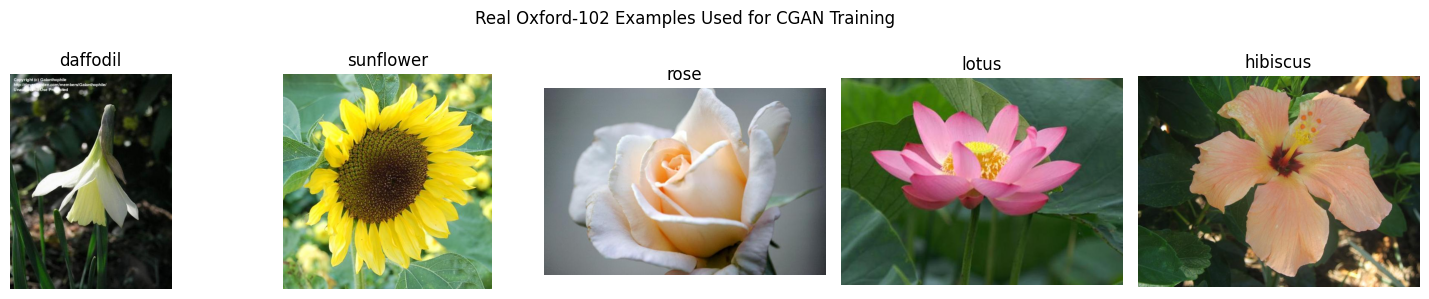

In [6]:
fig, axes = plt.subplots(1, len(SELECTED_CLASSES), figsize=(15, 3))
for ax, class_name in zip(axes, SELECTED_CLASSES):
    row = train_df[train_df["class_name"] == class_name].sample(1, random_state=SEED).iloc[0]
    img = Image.open(jpg_dir / row["filename"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(class_name)
    ax.axis("off")
plt.suptitle("Real Oxford-102 Examples Used for CGAN Training")
plt.tight_layout()
plt.show()


## 6. Image preprocessing and DataLoader

Images are center-cropped/resized to **64×64** and normalized to `[-1, 1]`, matching the Generator's `tanh` output.


In [7]:
IMAGE_SIZE = 64
BATCH_SIZE = 64

transform = transforms.Compose([
    transforms.Resize(72),
    transforms.CenterCrop(64),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

class FlowerCGANDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(self.image_dir / row["filename"]).convert("RGB")
        if self.transform:
            image = self.transform(image)
        label = torch.tensor(int(row["cgan_label"]), dtype=torch.long)
        return image, label

dataset = FlowerCGANDataset(train_df, jpg_dir, transform)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True,
                        num_workers=2, pin_memory=(DEVICE.type == "cuda"), drop_last=False)

images, labels_batch = next(iter(dataloader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels_batch.shape)


Image batch shape: torch.Size([64, 3, 64, 64])
Label batch shape: torch.Size([64])


## 7. CGAN architecture

### Generator
The Generator receives:
1. a random noise vector `z`, and
2. an embedding of the requested flower category.

These are concatenated and progressively upsampled into a 64×64 RGB image.

### Discriminator
The Discriminator receives both the image and its category. The category is embedded and expanded into a spatial label map, then concatenated with the image. It predicts whether the **image-category pair** is real or generated.


In [8]:
LATENT_DIM = 100
NUM_CLASSES = len(SELECTED_CLASSES)
LABEL_EMBED_DIM = 32
CHANNELS = 3

class Generator(nn.Module):
    def __init__(self, latent_dim=100, num_classes=5, embed_dim=32):
        super().__init__()
        self.label_embedding = nn.Embedding(num_classes, embed_dim)
        input_dim = latent_dim + embed_dim
        self.net = nn.Sequential(
            nn.ConvTranspose2d(input_dim, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512), nn.ReLU(True),
            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, CHANNELS, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, noise, labels):
        label_vec = self.label_embedding(labels)
        x = torch.cat([noise, label_vec], dim=1).unsqueeze(2).unsqueeze(3)
        return self.net(x)

class Discriminator(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.label_embedding = nn.Embedding(num_classes, IMAGE_SIZE * IMAGE_SIZE)
        self.net = nn.Sequential(
            nn.Conv2d(CHANNELS + 1, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(256, 512, 4, 2, 1, bias=False),
            nn.BatchNorm2d(512), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(512, 1, 4, 1, 0, bias=False)
        )

    def forward(self, images, labels):
        label_map = self.label_embedding(labels).view(-1, 1, IMAGE_SIZE, IMAGE_SIZE)
        x = torch.cat([images, label_map], dim=1)
        return self.net(x).view(-1)

def weights_init(m):
    classname = m.__class__.__name__
    if "Conv" in classname:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif "BatchNorm" in classname:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

G = Generator(LATENT_DIM, NUM_CLASSES, LABEL_EMBED_DIM).to(DEVICE)
D = Discriminator(NUM_CLASSES).to(DEVICE)
G.apply(weights_init)
D.apply(weights_init)

print("Generator parameters:", f"{sum(p.numel() for p in G.parameters()):,}")
print("Discriminator parameters:", f"{sum(p.numel() for p in D.parameters()):,}")


Generator parameters: 3,839,008
Discriminator parameters: 2,787,072


## 8. Training setup

Binary cross-entropy with logits is used for adversarial training. Adam optimizers use standard DCGAN-style settings.

`EPOCHS = 30` is a reasonable starting point on a Colab T4 GPU. For a quick test, change it to `5`. For better-looking results, you may increase it to `50` or more if runtime permits.


In [9]:
EPOCHS = 30
LR = 0.0002
BETA1 = 0.5

criterion = nn.BCEWithLogitsLoss()
optimizer_G = torch.optim.Adam(G.parameters(), lr=LR, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(D.parameters(), lr=LR, betas=(BETA1, 0.999))

# Fixed inputs make it easy to see progress for the same categories over time.
fixed_noise = torch.randn(NUM_CLASSES * 4, LATENT_DIM, device=DEVICE)
fixed_labels = torch.arange(NUM_CLASSES, device=DEVICE).repeat_interleave(4)

os.makedirs("task2_samples", exist_ok=True)
os.makedirs("task2_models", exist_ok=True)


## 9. Train the Conditional GAN

During each batch:
1. The Discriminator learns to classify real conditioned pairs as real.
2. It also learns to classify generated conditioned pairs as fake.
3. The Generator learns to fool the Discriminator while using the requested category condition.


In [10]:
g_losses = []
d_losses = []

for epoch in range(EPOCHS):
    G.train()
    D.train()
    epoch_g = 0.0
    epoch_d = 0.0
    batches = 0

    progress = tqdm(dataloader, desc=f"Epoch {epoch+1}/{EPOCHS}", leave=False)
    for real_images, real_labels in progress:
        real_images = real_images.to(DEVICE, non_blocking=True)
        real_labels = real_labels.to(DEVICE, non_blocking=True)
        batch_size = real_images.size(0)

        real_targets = torch.ones(batch_size, device=DEVICE)
        fake_targets = torch.zeros(batch_size, device=DEVICE)

        # ---- Train Discriminator ----
        optimizer_D.zero_grad()
        real_logits = D(real_images, real_labels)
        loss_real = criterion(real_logits, real_targets)

        noise = torch.randn(batch_size, LATENT_DIM, device=DEVICE)
        fake_labels = torch.randint(0, NUM_CLASSES, (batch_size,), device=DEVICE)
        fake_images = G(noise, fake_labels)
        fake_logits = D(fake_images.detach(), fake_labels)
        loss_fake = criterion(fake_logits, fake_targets)

        d_loss = loss_real + loss_fake
        d_loss.backward()
        optimizer_D.step()

        # ---- Train Generator ----
        optimizer_G.zero_grad()
        fake_logits_for_g = D(fake_images, fake_labels)
        g_loss = criterion(fake_logits_for_g, real_targets)
        g_loss.backward()
        optimizer_G.step()

        epoch_d += d_loss.item()
        epoch_g += g_loss.item()
        batches += 1
        progress.set_postfix(D=f"{d_loss.item():.3f}", G=f"{g_loss.item():.3f}")

    avg_d = epoch_d / batches
    avg_g = epoch_g / batches
    d_losses.append(avg_d)
    g_losses.append(avg_g)

    # Save a fixed sample grid every 5 epochs and on the final epoch.
    if (epoch + 1) % 5 == 0 or epoch == 0 or epoch + 1 == EPOCHS:
        G.eval()
        with torch.no_grad():
            samples = G(fixed_noise, fixed_labels).cpu()
        save_image(samples, f"task2_samples/epoch_{epoch+1:03d}.png", nrow=4, normalize=True, value_range=(-1, 1))

    print(f"Epoch [{epoch+1:02d}/{EPOCHS}]  D loss: {avg_d:.4f}  G loss: {avg_g:.4f}")

print("Training complete.")


Epoch 1/30:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch [01/30]  D loss: 1.2905  G loss: 5.3884


Epoch 2/30:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch [02/30]  D loss: 0.4762  G loss: 5.5991


Epoch 3/30:   0%|          | 0/9 [00:00<?, ?it/s]

...

Epoch 29/30:   0%|          | 0/9 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7962bfc19c60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7962bfc19c60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Exception ignored in:     <function _M

Epoch [29/30]  D loss: 1.0830  G loss: 4.6239


Epoch 30/30:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch [30/30]  D loss: 0.8883  G loss: 4.1511
Training complete.


## 10. Plot Generator and Discriminator losses


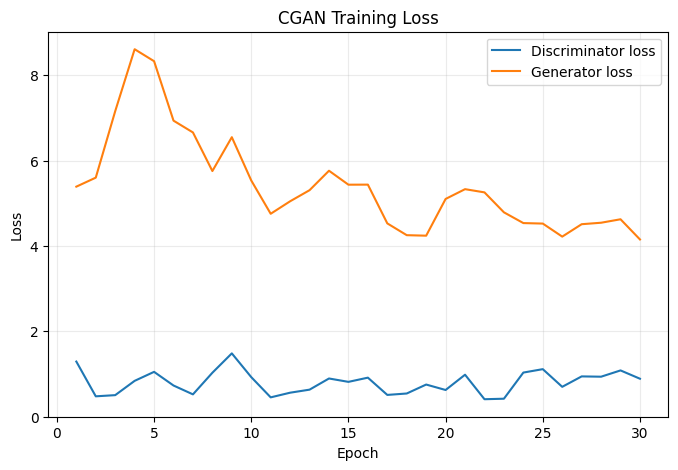

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), d_losses, label="Discriminator loss")
plt.plot(range(1, EPOCHS + 1), g_losses, label="Generator loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CGAN Training Loss")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


## 11. Generate category-controlled flower samples

Each row below corresponds to a requested flower category. This demonstrates the **conditional** part of the GAN.


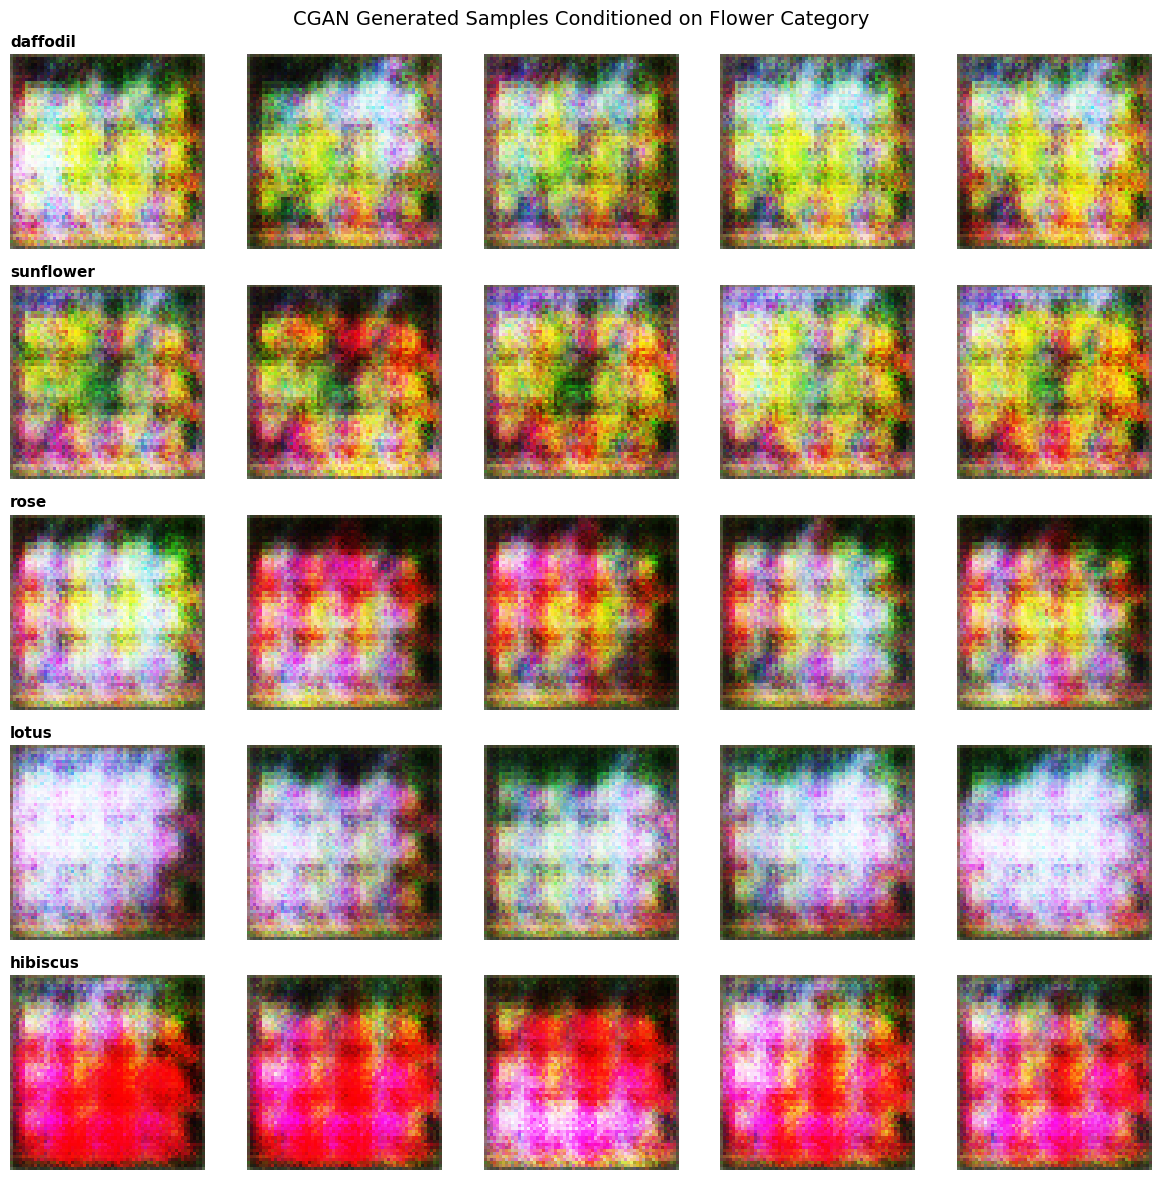

Saved: task2_generated_flowers.png


In [12]:
G.eval()
SAMPLES_PER_CLASS = 5

sample_noise = torch.randn(NUM_CLASSES * SAMPLES_PER_CLASS, LATENT_DIM, device=DEVICE)
sample_labels = torch.arange(NUM_CLASSES, device=DEVICE).repeat_interleave(SAMPLES_PER_CLASS)

with torch.no_grad():
    generated = G(sample_noise, sample_labels).cpu()

generated_display = (generated + 1) / 2

fig, axes = plt.subplots(NUM_CLASSES, SAMPLES_PER_CLASS, figsize=(12, 12))
for r, class_name in enumerate(SELECTED_CLASSES):
    for c in range(SAMPLES_PER_CLASS):
        idx = r * SAMPLES_PER_CLASS + c
        img = generated_display[idx].permute(1, 2, 0).clamp(0, 1)
        axes[r, c].imshow(img)
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(class_name, loc="left", fontsize=11, fontweight="bold")
plt.suptitle("CGAN Generated Samples Conditioned on Flower Category", fontsize=14)
plt.tight_layout()
plt.show()

save_image(generated, "task2_generated_flowers.png", nrow=SAMPLES_PER_CLASS,
           normalize=True, value_range=(-1, 1))
print("Saved: task2_generated_flowers.png")


## 12. Generate a flower from a chosen label

Change `REQUESTED_FLOWER` to any of the five categories and rerun this cell.


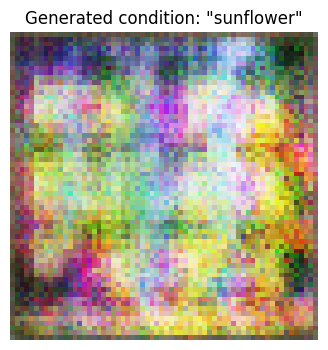

In [13]:
REQUESTED_FLOWER = "sunflower"  # daffodil, sunflower, rose, lotus, hibiscus

assert REQUESTED_FLOWER in class_to_cgan, f"Choose one of: {SELECTED_CLASSES}"
requested_label = torch.tensor([class_to_cgan[REQUESTED_FLOWER]], device=DEVICE)
noise = torch.randn(1, LATENT_DIM, device=DEVICE)

G.eval()
with torch.no_grad():
    generated_one = G(noise, requested_label).cpu()[0]

img = ((generated_one + 1) / 2).permute(1, 2, 0).clamp(0, 1)
plt.figure(figsize=(4, 4))
plt.imshow(img)
plt.title(f'Generated condition: "{REQUESTED_FLOWER}"')
plt.axis("off")
plt.show()


## 13. Save trained models and experiment information


In [14]:
torch.save({
    "model_state_dict": G.state_dict(),
    "selected_classes": SELECTED_CLASSES,
    "class_to_cgan": class_to_cgan,
    "latent_dim": LATENT_DIM,
    "label_embed_dim": LABEL_EMBED_DIM,
    "image_size": IMAGE_SIZE
}, "task2_models/cgan_generator.pth")

torch.save({
    "model_state_dict": D.state_dict(),
    "selected_classes": SELECTED_CLASSES,
    "class_to_cgan": class_to_cgan,
    "image_size": IMAGE_SIZE
}, "task2_models/cgan_discriminator.pth")

history_df = pd.DataFrame({
    "epoch": range(1, EPOCHS + 1),
    "generator_loss": g_losses,
    "discriminator_loss": d_losses
})
history_df.to_csv("task2_training_history.csv", index=False)

print("Saved task2_models/cgan_generator.pth")
print("Saved task2_models/cgan_discriminator.pth")
print("Saved task2_training_history.csv")


Saved task2_models/cgan_generator.pth
Saved task2_models/cgan_discriminator.pth
Saved task2_training_history.csv


## 14. Task 2 Summary and Conclusion

This experiment introduces **conditional inputs in GANs** using flower categories from the same Oxford-102 project. Unlike an unconditional GAN, the Generator is not driven by random noise alone: it also receives a learned representation of the requested category. The Discriminator likewise evaluates whether an image is realistic **for the supplied category**.

The generated images are intentionally low-resolution (64×64) because this task focuses on demonstrating the CGAN mechanism rather than photorealistic text-to-image generation. Task 5 can extend this baseline with an attention mechanism, while later tasks can use richer text embeddings and pre-trained text-to-image models.


In [15]:
print("===== TASK 2 SUMMARY =====")
print("Dataset: Oxford-102 Flowers")
print(f"Full dataset classes: {len(FLOWER_CLASSES)}")
print(f"CGAN experiment classes: {NUM_CLASSES}")
print("Selected categories:", ", ".join(SELECTED_CLASSES))
print(f"Training images used: {len(train_df)}")
print(f"Image resolution used by CGAN: {IMAGE_SIZE}x{IMAGE_SIZE}")
print(f"Latent noise dimension: {LATENT_DIM}")
print(f"Training epochs completed: {len(g_losses)}")
print(f"Final Generator loss: {g_losses[-1]:.4f}")
print(f"Final Discriminator loss: {d_losses[-1]:.4f}")
print("\nConclusion: The CGAN successfully implements category-conditioned image generation. "
      "Flower labels are embedded and supplied to both adversarial networks, allowing the "
      "generator to produce outputs according to a requested category. The quality of the "
      "generated images depends on training time, dataset size, and GAN stability; the model "
      "serves as the baseline for the attention-enhanced GAN experiment in Task 5.")


===== TASK 2 SUMMARY =====
Dataset: Oxford-102 Flowers
Full dataset classes: 102
CGAN experiment classes: 5
Selected categories: daffodil, sunflower, rose, lotus, hibiscus
Training images used: 559
Image resolution used by CGAN: 64x64
Latent noise dimension: 100
Training epochs completed: 30
Final Generator loss: 4.1511
Final Discriminator loss: 0.8883

Conclusion: The CGAN successfully implements category-conditioned image generation. Flower labels are embedded and supplied to both adversarial networks, allowing the generator to produce outputs according to a requested category. The quality of the generated images depends on training time, dataset size, and GAN stability; the model serves as the baseline for the attention-enhanced GAN experiment in Task 5.


## Files to keep for the final internship submission

After running all cells successfully, keep/download:

- This executed `.ipynb` notebook (with outputs visible)
- `task2_generated_flowers.png`
- `task2_training_history.csv`
- `task2_models/cgan_generator.pth`
- `task2_models/cgan_discriminator.pth`
- Useful sample images from the `task2_samples/` folder

For GitHub, the notebook, README/results, and representative generated images are usually more useful than uploading very large model files. Model weights can be included only if their size is reasonable.
